# DT401 Week 4 Section 3: Descriptive Statistics and Visualisation

**Module:** Data Fundamentals  
**Week:** 4 of 7  
**Section:** 3 of 3  
**Estimated Time:** 55 minutes

---

## Learning Objective

Use descriptive statistics and visualisation to gain insights and communicate findings.

By the end of this notebook, you will be able to:
- Calculate measures of central tendency (mean, median, mode)
- Calculate measures of dispersion (range, standard deviation)
- Understand data distributions and their business implications
- Create effective visualisations to communicate insights

---

## Context Recap

In Sections 1-2, you learned how to gather data and understand relationships between variables. Now we explore how to summarize and visualize data to extract actionable insights. These skills are essential for your Module Challenge Part A portfolio, where you'll demonstrate data analysis and communication capabilities.

---

## How to Use This Notebook

This notebook contains a mix of instructional text, Python code cells, and interactive exercises. Follow the instructions in each section, run the code cells to see outputs, and complete the exercises to reinforce your learning.

You will find several types of boxes throughout the notebook to guide your learning:

<div class="alert alert-block alert-warning">
<b>Reminder boxes:</b> <br>
These boxes contain important reminders about how this section relates to the overall module and your learning journey.
</div>

<div class="alert alert-block alert-info">
<b>Reflection boxes:</b> <br>
These have pointers as to what we should be looking for or comments on how to approach the topic discussed.
</div>

<div class="alert alert-block alert-success">
<b>Task boxes:</b> <br>
These have questions or tasks you should complete before progressing.

These may include hidden hints or solutions.
<details>
    <summary style="color:black;font-weight:bold">Click here for a hint</summary>

Hints will appear like this when you need guidance on tasks.

</details>

</div>

---

## Part 1: Measures of Central Tendency

### Visual Overview

```mermaid
flowchart TD
    A[Dataset] --> B{Which average to use?}
    B --> C[Mean - Arithmetic average]
    B --> D[Median - Middle value]
    B --> E[Mode - Most common]
    C --> F[Affected by outliers]
    D --> G[Robust to outliers]
    E --> H[Best for categories]
```

**What this diagram shows:**
Three measures describe "typical" values, each with different properties. Mean is sensitive to outliers; median is robust; mode works for any data type.

**Why this matters in your role:**
A charity reporting "average donation" of £500 might mislead if one donor gave £50,000. The median (£25) better represents typical donors, informing realistic fundraising targets.

---

### Worked Example: Temperature Averages

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load weather dataset
weather_df = pd.read_csv('../open-meteo-51.49N0.16W23m.csv', skiprows=3, low_memory=False)
weather_df.columns = [c.split(' ')[0].strip() for c in weather_df.columns]
weather_df = weather_df.rename(columns={
    'time': 'date',
    'temperature_2m': 'temperature',
    'wind_speed_10m': 'wind_speed',
    'relative_humidity_2m': 'relative_humidity'
})
weather_df = weather_df[weather_df['date'].str.match(r'^\d{4}-\d{2}-\d{2}T', na=False)].reset_index(drop=True)
for col in weather_df.columns[1:]:
    weather_df[col] = pd.to_numeric(weather_df[col], errors='coerce')
weather_df['date'] = pd.to_datetime(weather_df['date'])

# Calculate measures of central tendency
temp = weather_df['temperature'].dropna()
mean_temp = temp.mean()
median_temp = temp.median()
mode_temp = temp.mode()[0]  # Take first mode if multiple

print(f"Mean temperature: {mean_temp:.2f}°C")
print(f"Median temperature: {median_temp:.2f}°C")
print(f"Mode temperature: {mode_temp:.2f}°C")

Mean temperature: 11.92°C
Median temperature: 11.60°C
Mode temperature: 10.60°C


<div class="alert alert-block alert-info">
<b>What just happened?</b><br>

- **Mean:** Sum of all temperatures divided by count—most common "average"
- **Median:** Middle value when temperatures are sorted—represents 50th percentile
- **Mode:** Most frequently occurring temperature—less useful for continuous data

**Key lesson:** For temperature (normally distributed), mean and median are similar. When they differ significantly, the distribution is skewed.

</div>

**Business Context:**

A local council planning winter services uses mean temperature to estimate heating needs. However, if a few extreme cold days (outliers) pull the mean down, they might overestimate typical conditions. Median provides a more representative "typical day" for capacity planning.

### Visualizing Central Tendency

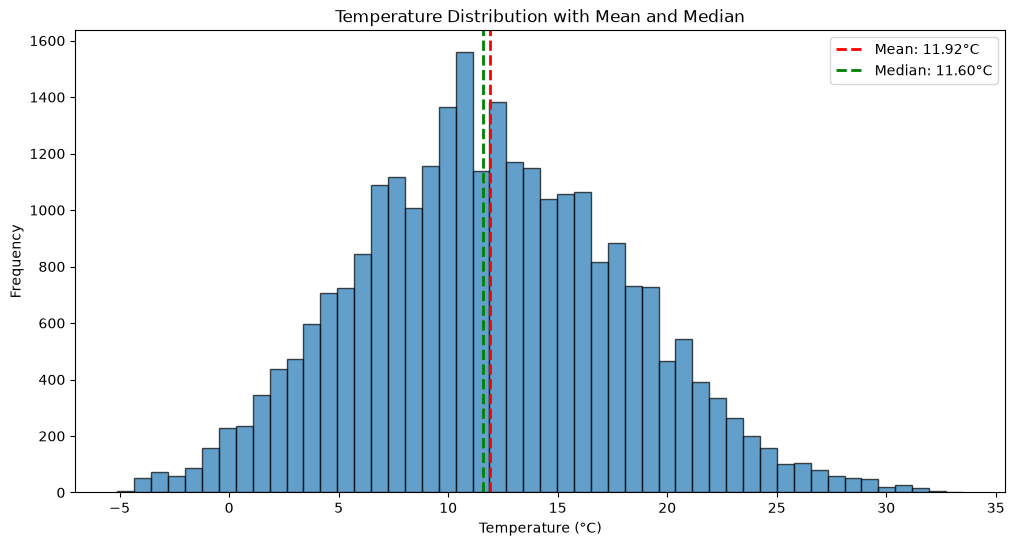

In [2]:
# Create histogram with mean and median marked
plt.figure(figsize=(12, 6))
plt.hist(temp, bins=50, alpha=0.7, edgecolor='black')
plt.axvline(mean_temp, color='red', linestyle='--', 
            linewidth=2, label=f'Mean: {mean_temp:.2f}°C')
plt.axvline(median_temp, color='green', linestyle='--', 
            linewidth=2, label=f'Median: {median_temp:.2f}°C')
plt.xlabel('Temperature (°C)')
plt.ylabel('Frequency')
plt.title('Temperature Distribution with Mean and Median')
plt.legend()
plt.show()

<div class="alert alert-block alert-info">
<b>What just happened?</b><br>

- The histogram shows the full distribution of temperatures
- Red line (mean) and green line (median) are close together
- This indicates a roughly symmetric distribution
- If distribution was skewed, mean and median would separate

**Key lesson:** Visualizing distribution reveals whether mean is appropriate. Skewed distributions need median for accurate representation.

</div>

---

## Part 2: Measures of Dispersion

### Visual Overview

```mermaid
flowchart LR
    A[Dispersion Measures] --> B[Range]
    A --> C[Quartiles]
    A --> D[Standard Deviation]
    B --> E[Max - Min]
    C --> F[25th, 50th, 75th percentiles]
    D --> G[Average distance from mean]
```

**What this diagram shows:**
Dispersion measures quantify spread. Range shows extremes; quartiles show distribution shape; standard deviation quantifies typical variation.

**Why this matters in your role:**
Two hospital wards might have the same mean length of stay (5 days), but one with high standard deviation (σ=3 days) needs more flexible capacity than one with low variation (σ=1 day).

---

### Worked Example: Temperature Variability

In [3]:
# Calculate measures of dispersion
range_temp = temp.max() - temp.min()
std_temp = temp.std()
q25 = temp.quantile(0.25)
q50 = temp.quantile(0.50)  # Median
q75 = temp.quantile(0.75)
iqr = q75 - q25  # Interquartile range

print(f"Range: {range_temp:.2f}°C (from {temp.min():.1f} to {temp.max():.1f})")
print(f"Standard deviation: {std_temp:.2f}°C")
print(f"\nQuartiles:")
print(f"  25th percentile (Q1): {q25:.2f}°C")
print(f"  50th percentile (Q2/Median): {q50:.2f}°C")
print(f"  75th percentile (Q3): {q75:.2f}°C")
print(f"  Interquartile range (IQR): {iqr:.2f}°C")

Range: 38.60°C (from -5.1 to 33.5)
Standard deviation: 6.16°C

Quartiles:
  25th percentile (Q1): 7.60°C
  50th percentile (Q2/Median): 11.60°C
  75th percentile (Q3): 16.10°C
  Interquartile range (IQR): 8.50°C


<div class="alert alert-block alert-info">
<b>What just happened?</b><br>

- **Range:** Total spread from coldest to warmest day
- **Standard deviation:** Typical deviation from mean—~68% of data within 1 SD
- **Quartiles:** Divide data into four equal parts
- **IQR:** Middle 50% of data—robust to outliers

**Key lesson:** Standard deviation quantifies variability. Higher SD means more unpredictable values.

</div>

**Business Interpretation:**

A retail clothing chain uses standard deviation to plan inventory:
- **Low SD (consistent temperatures):** Stock steady amounts of seasonal wear
- **High SD (variable temperatures):** Maintain diverse inventory to cover warm and cool days

Understanding variation is as important as understanding averages.

### Visualizing Dispersion with Box Plot

/tmp/ipykernel_56631/3538413055.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(temp, vert=False)


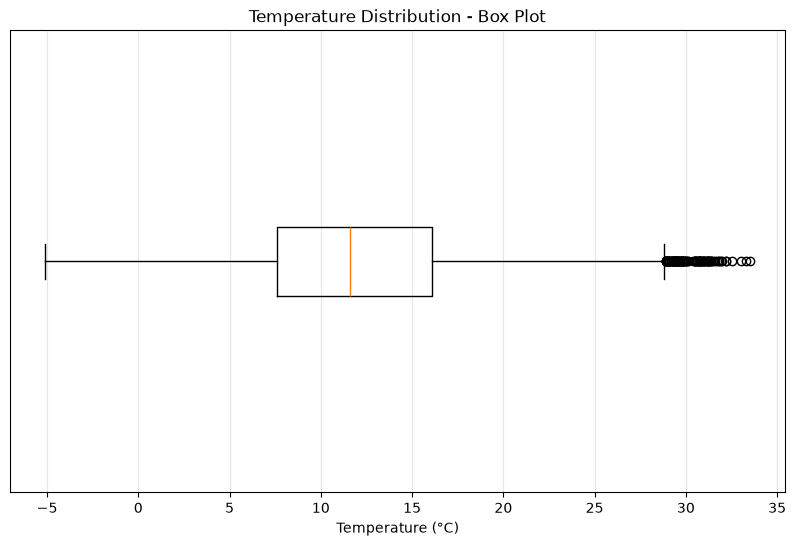


Box plot components:
- Box edges: Q1 (25th) and Q3 (75th percentiles)
- Line inside box: Median (Q2)
- Whiskers: Extend to 1.5 × IQR from box edges
- Points beyond whiskers: Potential outliers


In [4]:
# Create box plot showing quartiles and outliers
plt.figure(figsize=(10, 6))
plt.boxplot(temp, vert=False)
plt.xlabel('Temperature (°C)')
plt.title('Temperature Distribution - Box Plot')
plt.yticks([])
plt.grid(axis='x', alpha=0.3)
plt.show()

print("\nBox plot components:")
print("- Box edges: Q1 (25th) and Q3 (75th percentiles)")
print("- Line inside box: Median (Q2)")
print("- Whiskers: Extend to 1.5 × IQR from box edges")
print("- Points beyond whiskers: Potential outliers")

<div class="alert alert-block alert-warning">
<b>Reminder:</b> <br>
Box plots reveal distribution shape at a glance. Symmetric boxes indicate normal distribution; asymmetric boxes show skewness. Outliers appear as individual points.
</div>

---

## Part 3: Modified Task - Comparing Distributions

---

### Modified Task: Seasonal Temperature Variation

<div class="alert alert-block alert-success">
<b>Your turn:</b> <br>
Compare temperature distributions across seasons to understand variability patterns.

Complete the code to:
1. Group temperatures by season
2. Calculate mean and standard deviation for each season
3. Create box plots comparing seasons

<details>
    <summary style="color:black;font-weight:bold">Click here for a hint</summary>

Use the season function from Section 2:
```python
def get_season(month):
    if month in [12, 1, 2]: return 'Winter'
    elif month in [3, 4, 5]: return 'Spring'
    elif month in [6, 7, 8]: return 'Summer'
    else: return 'Autumn'
```

Then use `groupby('season')` to calculate statistics.

</details>

<details>
    <summary style="color:green;font-weight:bold">Click here for the solution</summary>

```python
# Define season function
def get_season(month):
    if month in [12, 1, 2]: return 'Winter'
    elif month in [3, 4, 5]: return 'Spring'
    elif month in [6, 7, 8]: return 'Summer'
    else: return 'Autumn'

# Add season column
weather_df['month'] = weather_df['date'].dt.month
weather_df['season'] = weather_df['month'].apply(get_season)

# Calculate statistics by season
seasonal_stats = weather_df.groupby('season')['temperature'].agg([
    ('Mean', 'mean'),
    ('Std Dev', 'std'),
    ('Min', 'min'),
    ('Max', 'max')
]).round(2)

print("Seasonal Temperature Statistics:")
print(seasonal_stats)

# Create comparative box plots
plt.figure(figsize=(12, 6))
season_order = ['Winter', 'Spring', 'Summer', 'Autumn']
weather_clean = weather_df[['season', 'temperature']].dropna()
sns.boxplot(data=weather_clean, x='season', y='temperature', 
            order=season_order)
plt.xlabel('Season')
plt.ylabel('Temperature (°C)')
plt.title('Temperature Distribution by Season')
plt.grid(axis='y', alpha=0.3)
plt.show()
```

</details>

</div>

Seasonal Temperature Statistics:
         Mean  Std Dev  Min   Max
season                           
Autumn  12.35     4.98 -2.8  31.4
Spring  10.78     4.66 -3.6  28.5
Summer  18.15     4.26  6.2  33.5
Winter   6.32     3.91 -5.1  16.6


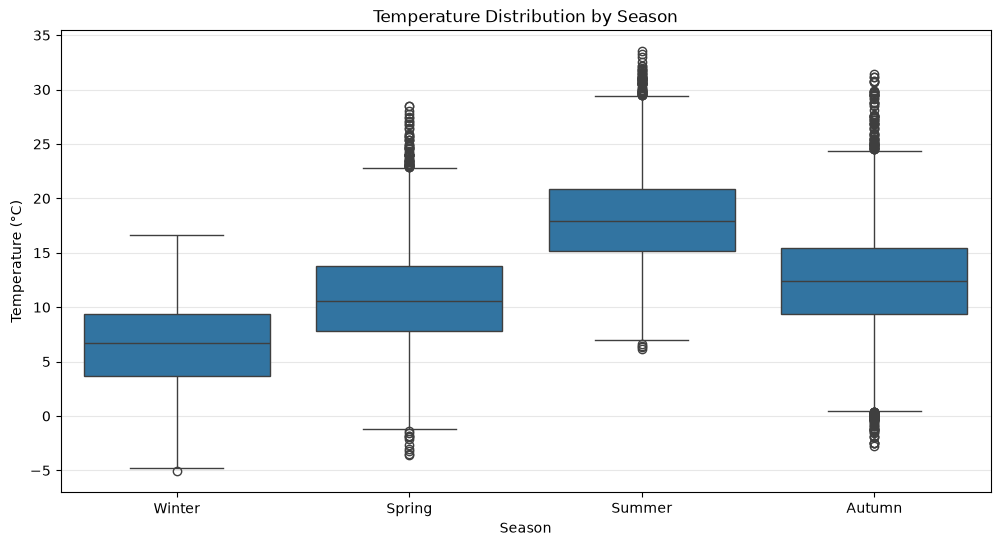

In [5]:
# Define season function
def get_season(month):
    if month in [12, 1, 2]: return 'Winter'
    elif month in [3, 4, 5]: return 'Spring'
    elif month in [6, 7, 8]: return 'Summer'
    else: return 'Autumn'

# Add season column
weather_df['month'] = weather_df['date'].dt.month
weather_df['season'] = weather_df['month'].apply(get_season)

# Calculate statistics by season
seasonal_stats = weather_df.groupby('season')['temperature'].agg([
    ('Mean', 'mean'),
    ('Std Dev', 'std'),
    ('Min', 'min'),
    ('Max', 'max')
]).round(2)

print("Seasonal Temperature Statistics:")
print(seasonal_stats)

# Create comparative box plots
plt.figure(figsize=(12, 6))
season_order = ['Winter', 'Spring', 'Summer', 'Autumn']
weather_clean = weather_df[['season', 'temperature']].dropna()
sns.boxplot(data=weather_clean, x='season', y='temperature', 
            order=season_order)
plt.xlabel('Season')
plt.ylabel('Temperature (°C)')
plt.title('Temperature Distribution by Season')
plt.grid(axis='y', alpha=0.3)
plt.show()

**Interpretation questions:**

1. Which season has the highest mean temperature? Lowest?
2. Which season shows the most variability (highest standard deviation)?
3. Are there any outliers? What might they represent?
4. How would these patterns inform business decisions in your sector?

---

## Part 4: Data Visualisation Best Practices

Let's explore different visualisation types and when to use them.

### Visualisation 1: Time Series Line Graph

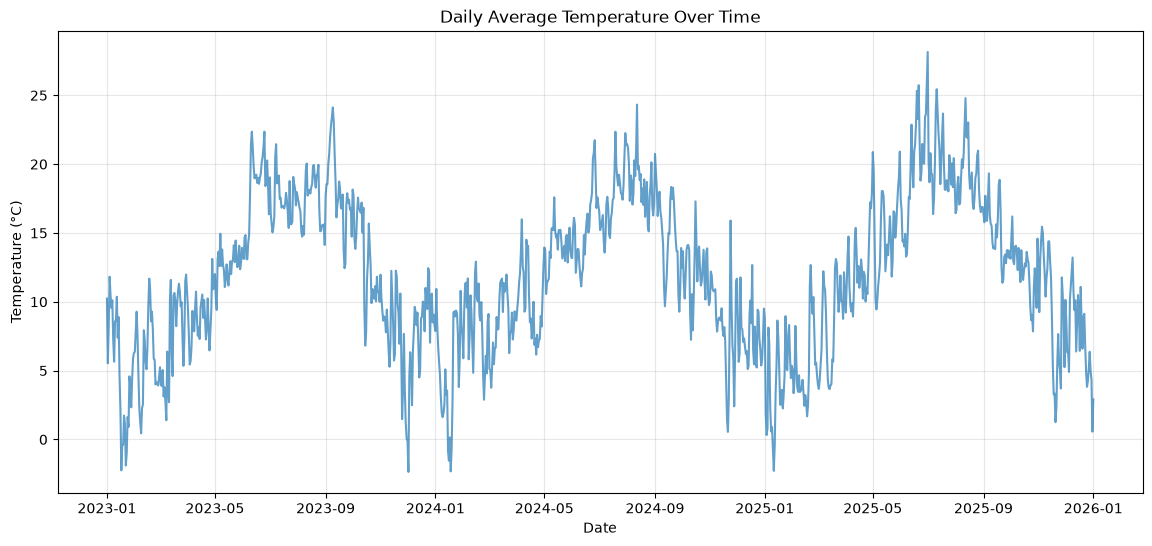

In [6]:
# Aggregate to daily averages
daily_temp = weather_df.groupby(weather_df['date'].dt.date)['temperature'].mean()

# Plot time series
plt.figure(figsize=(14, 6))
plt.plot(daily_temp.index, daily_temp.values, alpha=0.7)
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.title('Daily Average Temperature Over Time')
plt.grid(alpha=0.3)
plt.show()

<div class="alert alert-block alert-info">
<b>What just happened?</b><br>

- We aggregated hourly data to daily averages
- Line graph shows temporal trends and seasonal cycles
- Clear seasonal pattern visible (warm summers, cool winters)

**Key lesson:** Line graphs are ideal for showing change over time and identifying trends.

**Business application:** A charity tracks monthly donation volumes over years. Line graphs reveal seasonal patterns (December spike) and long-term trends (growing or declining support).

</div>

### Visualisation 2: Scatterplot for Relationships

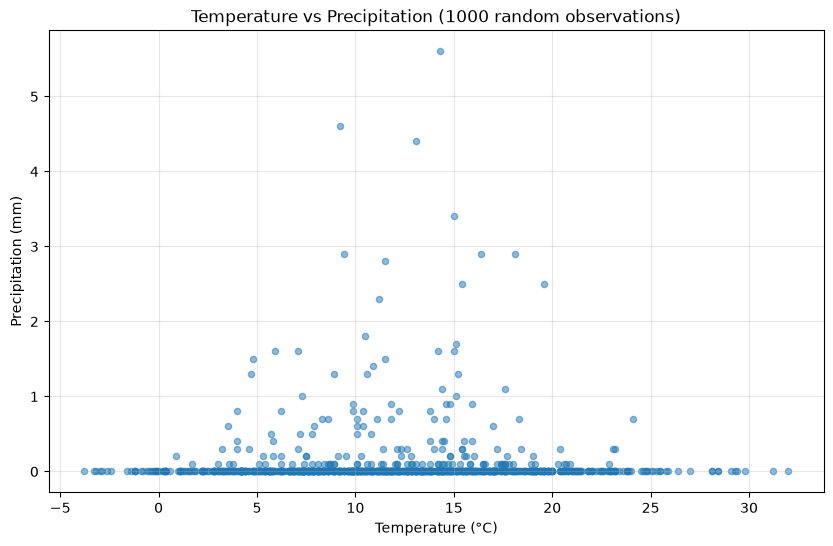

Correlation: 0.014


In [7]:
# Scatter plot: temperature vs precipitation
clean_data = weather_df[['temperature', 'precipitation']].dropna()
sample_data = clean_data.sample(n=1000)  # Sample for clarity

plt.figure(figsize=(10, 6))
plt.scatter(sample_data['temperature'], sample_data['precipitation'], 
            alpha=0.5, s=20)
plt.xlabel('Temperature (°C)')
plt.ylabel('Precipitation (mm)')
plt.title('Temperature vs Precipitation (1000 random observations)')
plt.grid(alpha=0.3)
plt.show()

corr = clean_data['temperature'].corr(clean_data['precipitation'])
print(f"Correlation: {corr:.3f}")

<div class="alert alert-block alert-info">
<b>What just happened?</b><br>

- Scatterplot shows relationship between two continuous variables
- Each point represents one observation
- Correlation coefficient quantifies relationship strength

**Key lesson:** Scatterplots reveal correlations visually. Tight patterns indicate strong relationships; scattered points show weak correlation.

**Business application:** Finance sector plots account balance vs. transaction frequency. Strong positive correlation suggests engaged customers; outliers (high balance, low activity) may need retention outreach.

</div>

### Visualisation 3: Histogram for Distribution

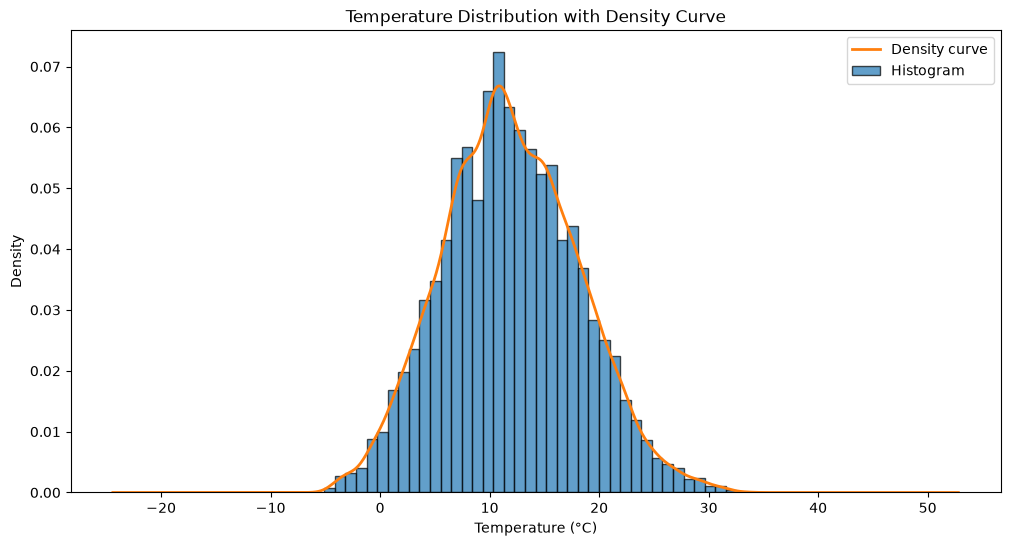

In [8]:
# Histogram with density curve
plt.figure(figsize=(12, 6))
plt.hist(temp, bins=40, alpha=0.7, edgecolor='black', density=True)
temp.plot(kind='density', linewidth=2)
plt.xlabel('Temperature (°C)')
plt.ylabel('Density')
plt.title('Temperature Distribution with Density Curve')
plt.legend(['Density curve', 'Histogram'])
plt.show()

<div class="alert alert-block alert-info">
<b>What just happened?</b><br>

- Histogram shows frequency of values in bins
- Density curve smooths the distribution for easier interpretation
- Shape reveals whether data is normal, skewed, or multimodal

**Key lesson:** Distribution shape informs which statistical methods are appropriate. Normal distributions support parametric tests; skewed distributions may need non-parametric approaches.

**Business application:** A local government analyzes response time distribution for service requests. Bimodal distribution (two peaks) reveals two distinct groups—routine requests (quick) and complex cases (slow)—requiring different resource allocation strategies.

</div>

---

## Part 5: Independent Task - Complete Data Analysis

### Your Challenge

Perform a complete descriptive analysis of precipitation data, applying all techniques learned.

**Your task:**
1. Calculate all descriptive statistics (mean, median, mode, std dev, quartiles)
2. Create at least 3 different visualisations
3. Identify patterns, outliers, or insights
4. Write a business interpretation connecting findings to decisions
5. Suggest follow-up questions or analyses

<div class="alert alert-block alert-success">
<b>Your turn:</b> <br>
Analyze the precipitation variable and present your findings.

<details>
    <summary style="color:black;font-weight:bold">Click here for a hint</summary>

**Suggested structure:**
1. Start with descriptive statistics
2. Create a histogram to see distribution shape
3. Create a box plot to identify outliers
4. Create a time series or seasonal analysis
5. Summarize what the data reveals about rainfall patterns
6. Connect to a business scenario (council planning, agriculture, construction, events management)

</details>

<details>
    <summary style="color:green;font-weight:bold">Click here for an example solution</summary>

```python
# 1. Descriptive Statistics
precip = weather_df['precipitation'].dropna()
print("=== PRECIPITATION ANALYSIS ===")
print(f"\nDescriptive Statistics:")
print(f"  Mean: {precip.mean():.2f} mm")
print(f"  Median: {precip.median():.2f} mm")
print(f"  Std Dev: {precip.std():.2f} mm")
print(f"  Range: {precip.min():.2f} to {precip.max():.2f} mm")
print(f"  Q1: {precip.quantile(0.25):.2f}, Q3: {precip.quantile(0.75):.2f}")

# Days with measurable rain
rainy_days = (precip > 0).sum()
total_days = len(precip)
print(f"\nRainy days: {rainy_days} of {total_days} ({100*rainy_days/total_days:.1f}%)")

# 2. Histogram
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.hist(precip[precip > 0], bins=30, edgecolor='black', alpha=0.7)
plt.xlabel('Precipitation (mm)')
plt.ylabel('Frequency')
plt.title('Distribution of Precipitation (rainy days only)')

# 3. Box plot by season
plt.subplot(1, 2, 2)
season_precip = weather_df[['season', 'precipitation']].dropna()
sns.boxplot(data=season_precip, x='season', y='precipitation',
            order=['Winter', 'Spring', 'Summer', 'Autumn'])
plt.ylabel('Precipitation (mm)')
plt.title('Precipitation by Season')
plt.tight_layout()
plt.show()

# 4. Business Interpretation
print("\n=== BUSINESS INSIGHTS ===")
print("\nKey findings:")
print("1. Precipitation is highly skewed (mean > median) - most days have little/no rain")
print("2. Occasional heavy rainfall events pull the average up")
print("3. Seasonal variation exists but may be less than expected")
print("\nBusiness application (Construction Sector):")
print("- Schedule outdoor work when sustained dry periods are most likely")
print("- Budget for rain delays based on frequency, not just total rainfall")
print("- Plan equipment rental around low-precipitation months")
print("\nFollow-up questions:")
print("- What time of day does rain typically occur?")
print("- Are there multi-day dry spells suitable for major outdoor projects?")
print("- How does precipitation correlate with wind speed (affecting crane operations)?")
```

</details>

</div>

=== PRECIPITATION ANALYSIS ===

Descriptive Statistics:
Mean: 0.09 mm
Median: 0.00 mm
Mode: 0.00 mm
Standard deviation: 0.37 mm
Minimum: 0.00 mm
Maximum: 9.70 mm
Q1: 0.00 mm
Q3: 0.00 mm
IQR: 0.00 mm
Observations with rain: 4,301
Percentage with rain: 16.3%


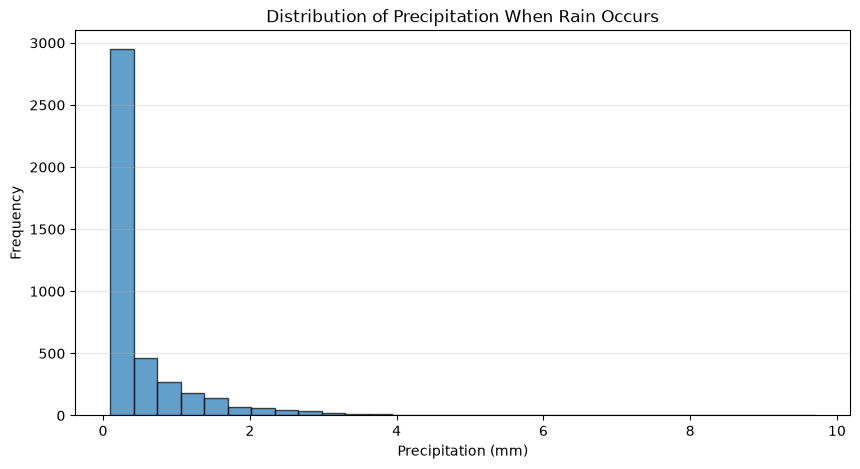

/tmp/ipykernel_56631/1697522027.py:40: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(precip, vert=False)


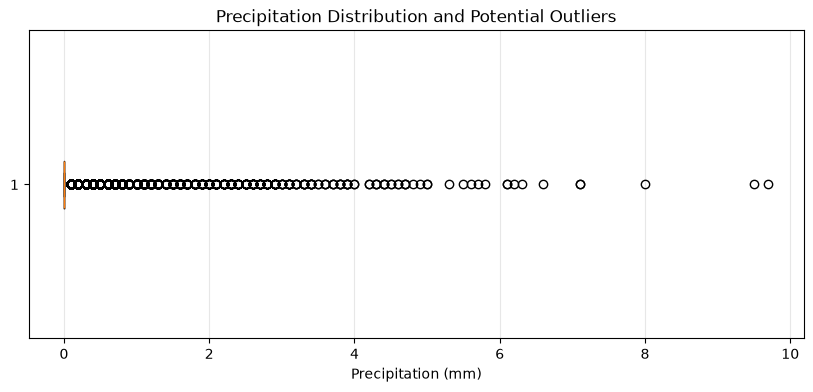

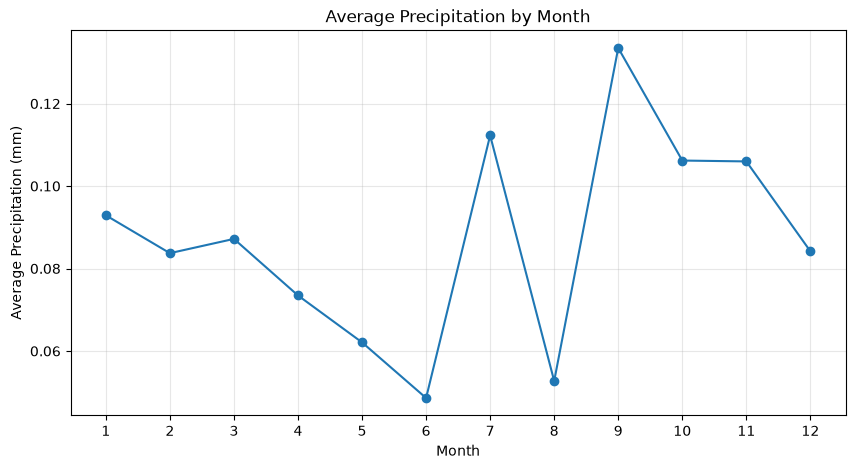


=== PATTERNS AND OUTLIERS ===
Potential high-rainfall outliers: 4301
Highest recorded precipitation: 9.70 mm
The distribution is positively skewed: a relatively small number of high-rainfall observations increase the mean.

=== BUSINESS INTERPRETATION ===
For Supply, Trading and Shipping, weather data can provide useful context when assessing energy-market conditions.
The distribution and variability of precipitation matter because averages alone can hide infrequent extreme events.
Analysis should therefore consider both typical conditions and the frequency and magnitude of extremes rather than relying only on the mean.

=== FOLLOW-UP QUESTIONS ===
1. How does precipitation vary between seasons and years?
2. Are extreme rainfall events becoming more frequent?
3. How does precipitation relate to temperature and wind speed?
4. Could precipitation patterns be compared with relevant energy supply, demand or price data?


In [9]:
# 1. Descriptive statistics

precip = weather_df['precipitation'].dropna()

print("=== PRECIPITATION ANALYSIS ===")

print("\nDescriptive Statistics:")
print(f"Mean: {precip.mean():.2f} mm")
print(f"Median: {precip.median():.2f} mm")
print(f"Mode: {precip.mode().iloc[0]:.2f} mm")
print(f"Standard deviation: {precip.std():.2f} mm")
print(f"Minimum: {precip.min():.2f} mm")
print(f"Maximum: {precip.max():.2f} mm")
print(f"Q1: {precip.quantile(0.25):.2f} mm")
print(f"Q3: {precip.quantile(0.75):.2f} mm")

# Additional measures
iqr = precip.quantile(0.75) - precip.quantile(0.25)
print(f"IQR: {iqr:.2f} mm")

rainy = precip[precip > 0]
print(f"Observations with rain: {len(rainy):,}")
print(f"Percentage with rain: {len(rainy) / len(precip) * 100:.1f}%")


# 2. VISUALISATIONS

# Visualisation 1: Histogram
plt.figure(figsize=(10, 5))
plt.hist(rainy, bins=30, edgecolor='black', alpha=0.7)
plt.xlabel('Precipitation (mm)')
plt.ylabel('Frequency')
plt.title('Distribution of Precipitation When Rain Occurs')
plt.grid(axis='y', alpha=0.3)
plt.show()


# Visualisation 2: Box plot
plt.figure(figsize=(10, 4))
plt.boxplot(precip, vert=False)
plt.xlabel('Precipitation (mm)')
plt.title('Precipitation Distribution and Potential Outliers')
plt.grid(axis='x', alpha=0.3)
plt.show()


# Visualisation 3: Monthly average precipitation
weather_df['month'] = weather_df['date'].dt.month

monthly_precip = weather_df.groupby(
    'month'
)['precipitation'].mean()

plt.figure(figsize=(10, 5))
plt.plot(
    monthly_precip.index,
    monthly_precip.values,
    marker='o'
)
plt.xlabel('Month')
plt.ylabel('Average Precipitation (mm)')
plt.title('Average Precipitation by Month')
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.show()


# 3. IDENTIFY PATTERNS AND OUTLIERS

q1 = precip.quantile(0.25)
q3 = precip.quantile(0.75)
iqr = q3 - q1
upper_limit = q3 + (1.5 * iqr)

outliers = precip[precip > upper_limit]

print("\n=== PATTERNS AND OUTLIERS ===")
print(f"Potential high-rainfall outliers: {len(outliers)}")
print(f"Highest recorded precipitation: {precip.max():.2f} mm")

if precip.mean() > precip.median():
    print(
        "The distribution is positively skewed: "
        "a relatively small number of high-rainfall "
        "observations increase the mean."
    )


# 4. BUSINESS INTERPRETATION

print("\n=== BUSINESS INTERPRETATION ===")
print(
    "For Supply, Trading and Shipping, weather data can provide "
    "useful context when assessing energy-market conditions."
)
print(
    "The distribution and variability of precipitation matter "
    "because averages alone can hide infrequent extreme events."
)
print(
    "Analysis should therefore consider both typical conditions "
    "and the frequency and magnitude of extremes rather than "
    "relying only on the mean."
)


# 5. FOLLOW-UP QUESTIONS

print("\n=== FOLLOW-UP QUESTIONS ===")
print("1. How does precipitation vary between seasons and years?")
print("2. Are extreme rainfall events becoming more frequent?")
print("3. How does precipitation relate to temperature and wind speed?")
print(
    "4. Could precipitation patterns be compared with relevant "
    "energy supply, demand or price data?"
)


**Write your business interpretation here:**

**Key findings:**
Precipitation is likely to be unevenly distributed, with many observations recording little or no rainfall and a smaller number of high rainfall observations. This means the mean alone may not represent typical conditions, so I would consider the median, standard deviation, quartiles and visual distribution together. Potential outliers should not automatically be removed because unusually high rainfall may represent genuine extreme weather rather than data errors.

**Business application (choose your sector):**
Weather can influence energy supply and demand, so understanding both normal conditions and extreme events can provide useful context for market analysis. However, precipitation should not be interpreted in isolation. I would combine it with other relevant variables before drawing a commercial conclusion.

**Follow-up questions:**
How does rainfall vary seasonally and between years?
Are extreme rainfall events becoming more frequent?

**Success criteria:**
- Complete descriptive statistics calculated and interpreted
- At least 3 different visualisation types created
- Patterns or outliers identified and explained
- Clear business interpretation connecting data to decisions
- Thoughtful follow-up questions proposed

**Portfolio note:** This complete analysis demonstrates your ability to explore data, extract insights, and communicate findings effectively—key skills for your Module Challenge Part A portfolio.

---

## Reflection

Reflect on the following question and record your thoughts in the cell below. Ground your answer in an example from your workplace, using **approximately 150 words** in total.

Your answer here forms part of your Module Challenge Part A portfolio and is assessed against **MLO3:** *Select and apply appropriate data-gathering methods for a given data analysis scenario*.

Where you draw on external sources, cite them in Harvard style. This does not count towards your word count.

Once you commit your notebook, your Coach will be able to provide feedback on your response. You can develop your answer further before your final submission.

<div class="alert alert-block alert-info">

1. Think of a recent presentation or report in your organisation. What visualisation types were used? Were they effective? What would you change?

</div>

*Write your responses here.*

1. In Supply, Trading and Shipping, I regularly see time series line charts used in market analysis to show how prices, inventories or other market variables change over time. I find these effective because they make trends, turning points and unusual movements easy to identify. However, a line chart can become misleading or difficult to interpret if too many series are included or if the selected time period hides important context. I would therefore keep the visual focused on the variables relevant to the business question and supplement it with appropriate descriptive statistics. For example, when analysing a volatile market variable, an average alone could conceal significant variation or extreme observations. Combining a clear time series visual with measures such as the median or standard deviation would give the stakeholder a more balanced view and reduce the risk of making a decision from an unrepresentative summary.

References (if applicable):

---

## Summary

**You have completed Week 4 Section 3.** You can now:

- Calculated and compared the mean, median, and mode of temperature readings from the weather dataset, and visualised them on a histogram to check for skew
- Calculated the range, standard deviation, and quartiles for temperature, then used a box plot to visualise spread and check for outliers
- Compared seasonal temperature distributions by grouping the weather data and calculating mean and standard deviation per season
- Produced a time series line graph, a scatterplot, and a histogram with density curve using the weather dataset, matching each chart type to the question it answers best
- Ran a complete descriptive analysis of the precipitation variable, combining summary statistics, multiple visualisations, and a business interpretation

**Key takeaways:**

- Mean is pulled by outliers. Median stays robust. When the two diverge, the underlying distribution is skewed
- Line graphs suit change over time, scatterplots suit relationships between two variables, and histograms suit distribution shape

**What comes next:**

- **Week 5 Section 1** introduces the data analysis lifecycle: its six stages, the Achieve-Measure-Verify framework, and how to engage stakeholders throughout the process

**Action items:**

1. Save this notebook (Ctrl+S or Cmd+S)
2. Commit and push your work to your GitHub repository with the commit message `"Complete Week 4 Section 3 Descriptive Statistics and Visualisation"`
3. Make sure the repository shows your latest commit and that all files are up to date
4. Share a link to your repository with your Coach in the DT401.4 component on Aptem